# K-Means Clustering Project – Facebook Live Dataset

## Objective
Apply **K-Means Clustering**, an unsupervised machine-learning algorithm, to group Facebook Live posts according to their engagement characteristics.

**Dataset:** `Live.csv`

> In this revised notebook, `status_type` is kept for interpretation only and is **not used as a target variable**. K-Means is unsupervised, so comparing cluster labels directly with `status_type` as an "accuracy" score is not appropriate.

#### 1. Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

%matplotlib inline
sns.set_theme(style="whitegrid")

import warnings
warnings.filterwarnings("ignore")

#### 2. Import dataset

In [3]:
df =pd.read_csv("iris.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


#### 3. Exploratory Data Analysis

In [4]:
df.shape

(150, 6)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [6]:
# Check missing values
df.isnull().sum()

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [7]:
# Statistical summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,150.0,75.500000,43.445368,1.0,38.25,75.50,112.75,150.0
SepalLengthCm,150.0,5.843333,0.828066,4.3,5.10,5.80,6.40,7.9
SepalWidthCm,150.0,3.054000,0.433594,2.0,2.80,3.00,3.30,4.4
PetalLengthCm,150.0,3.758667,1.764420,1.0,1.60,4.35,5.10,6.9
PetalWidthCm,150.0,1.198667,0.763161,0.1,0.30,1.30,1.80,2.5


In [28]:
# Distribution of post types
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [29]:
counts = df["status_type"].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values)
plt.title("Distribution of Facebook Post Types")
plt.xlabel("Status Type")
plt.ylabel("Number of Posts")
plt.show()

KeyError: 'status_type'

#### 
4. Data Preparation

The dataset contains:
- `status_id` and `status_published`: identifier/time-text fields that are not suitable for numerical clustering.
- `Column1`–`Column4`: empty/redundant columns in this dataset.
- `status_type`: categorical information about the post type. It is retained for later interpretation, but it is not used to form the clusters.
- Engagement variables such as reactions, comments, shares and different reaction types are used as clustering features.

In [9]:
# Create a copy
data = df.copy()

# Remove identifier/text fields and empty redundant columns
drop_cols = [
    "status_id", "status_published",
    "Column1", "Column2", "Column3", "Column4"
]
data.drop(columns=drop_cols, inplace=True)

data.head()

KeyError: "['status_id', 'status_published', 'Column1', 'Column2', 'Column3', 'Column4'] not found in axis"

In [ ]:
# Select numerical engagement features only
features = [
    "num_reactions", "num_comments", "num_shares",
    "num_likes", "num_loves", "num_wows",
    "num_hahas", "num_sads", "num_angrys"
]

X = data[features].copy()

print("Features used for clustering:")
print(features)
print("\nMissing values:")
print(X.isnull().sum())

#### 5. Feature Transformation and Scaling

Engagement counts are highly skewed because a small number of posts can have very large engagement values. We therefore use `log1p()` before standardization.

`StandardScaler` puts the transformed features on a comparable scale so that variables with larger numerical values do not dominate the distance calculation.

In [10]:
# Handle missing values, if any
X = X.fillna(X.median())

# Reduce strong right-skew in count variables
X_log = np.log1p(X)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

X_scaled = pd.DataFrame(X_scaled, columns=features)
X_scaled.head()

NameError: name 'X' is not defined

#### 6. Find the Optimal Number of Clusters – Elbow Method

In [11]:
inertia = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker="o")
plt.title("Elbow Method for Selecting K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.show()

NameError: name 'X_scaled' is not defined

**Interpretation:** The elbow plot shows how within-cluster variation decreases as K increases. The elbow is used as one indication of a suitable K; it should be considered together with a cluster-quality measure such as the silhouette score.

#### 7. Silhouette Score

In [12]:
silhouette_scores = {}

for k in k_values:
    model = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

silhouette_scores

NameError: name 'X_scaled' is not defined

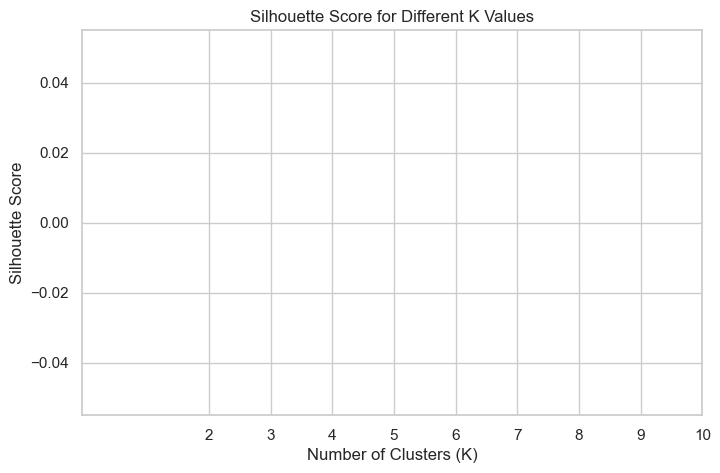

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(list(silhouette_scores.keys()), list(silhouette_scores.values()), marker="o")
plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.show()

In [14]:
# Select the K with the highest silhouette score
optimal_k = max(silhouette_scores, key=silhouette_scores.get)

print("Optimal K based on highest silhouette score:", optimal_k)
print("Silhouette score:", round(silhouette_scores[optimal_k], 4))

ValueError: max() iterable argument is empty

#### 8. Build the Final K-Means Model

In [15]:
kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=10,
    random_state=42
)

cluster_labels = kmeans.fit_predict(X_scaled)

print("Number of clusters:", optimal_k)
print("Final inertia:", round(kmeans.inertia_, 2))
print("Final silhouette score:", round(silhouette_score(X_scaled, cluster_labels), 4))

NameError: name 'optimal_k' is not defined

#### 9. Add Cluster Labels to the Dataset

In [16]:
result = data.copy()
result["Cluster"] = cluster_labels

result.head()

NameError: name 'cluster_labels' is not defined

In [17]:
# Number of records in each cluster
cluster_counts = result["Cluster"].value_counts().sort_index()
cluster_counts

KeyError: 'Cluster'

In [18]:
cluster_counts = result["Cluster"].value_counts().sort_index()
plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.title("Number of Posts in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Posts")
plt.show()

KeyError: 'Cluster'

#### 10. Cluster Profile

In [19]:
# Mean engagement values for each cluster
cluster_profile = result.groupby("Cluster")[features].mean().round(2)
cluster_profile

KeyError: 'Cluster'

In [ ]:
# Median engagement values are also useful because engagement is skewed
cluster_median = result.groupby("Cluster")[features].median().round(2)
cluster_median

### Interpreting the clusters

Use the cluster profile above to describe the groups in terms of engagement. For example, a cluster with relatively high values across reactions, comments and shares can be described as a **high-engagement group**, while a cluster with consistently lower values can be described as a **low-engagement group**.

The cluster number itself (0, 1, …) has no inherent meaning; the profile of each cluster determines its interpretation.

#### 11. PCA Visualization of the Clusters

In [20]:
# Reduce the standardized feature space to two dimensions for visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels
})

print("Explained variance by PC1 and PC2:",
      round(pca.explained_variance_ratio_[0], 4),
      round(pca.explained_variance_ratio_[1], 4))
print("Total explained variance:",
      round(pca.explained_variance_ratio_.sum(), 4))

NameError: name 'X_scaled' is not defined

In [21]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.65
)
plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()

NameError: name 'pca_df' is not defined

<Figure size 900x600 with 0 Axes>

#### 12. Optional Interpretation Using `status_type`

In [22]:

# This does NOT measure clustering accuracy.
# It only shows the distribution of post types inside each cluster.
cluster_status = pd.crosstab(
    result["Cluster"],
    result["status_type"],
    normalize="index"
).round(3)

cluster_status

KeyError: 'Cluster'

In [23]:
cluster_status.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Post-Type Composition of Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Proportion")
plt.legend(title="Status Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

NameError: name 'cluster_status' is not defined

#### 13. Final Results and Conclusion

1. The Facebook Live dataset was loaded and explored.
2. Identifier/text fields and empty redundant columns were removed.
3. Engagement variables were selected as the features for clustering.
4. `log1p()` transformation and standardization were applied to reduce the effect of highly skewed engagement counts.
5. The Elbow Method and Silhouette Score were used to investigate the suitable number of clusters.
6. The final K-Means model was trained using the selected `K`.
7. Cluster sizes, cluster profiles and a PCA visualization were generated.
8. `status_type` was used only for post-clustering interpretation.

**Important:** K-Means is an unsupervised algorithm. Therefore, the cluster labels should not be treated as class labels, and a conventional classification accuracy such as `correct_labels / total_samples` is not an appropriate evaluation of K-Means. In this notebook, **inertia and silhouette score** are used to evaluate clustering quality.

## Key K-Means Concepts

- **Centroid:** Mean position of all observations in a cluster.
- **Inertia:** Sum of squared distances of observations from their assigned cluster centroid. Lower values generally indicate tighter clusters, but inertia always decreases as K increases.
- **Silhouette Score:** Measures how well each observation fits its own cluster compared with other clusters. Higher values generally indicate better-separated clusters.
- **Elbow Method:** Plots inertia against K and looks for a point where additional clusters provide diminishing improvement.
- **K-Means++:** Initialization strategy that generally gives better starting centroids than purely random initialization.
- **PCA:** Used here only to visualize high-dimensional clusters in two dimensions.